In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Customer-Churn-Prediction.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
df.shape

(7043, 21)

<Axes: xlabel='count', ylabel='Churn'>

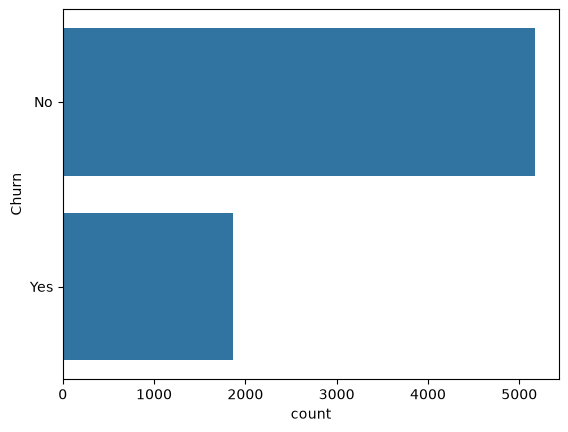

In [4]:
sns.countplot(df['Churn'])


In [6]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
Churned = df[df.Churn == 'Yes'].shape[0]
retained = df[df.Churn == 'No'].shape[0]

Customer left the company

In [8]:
ch_per = ((Churned /(Churned+retained)) * 100)
ch_per

26.536987079369588

Customer Stayed the company

In [9]:
re_per = ((retained /(Churned+retained)) * 100)
re_per

73.4630129206304

In [10]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162289,32.370865,64.761692
std,0.368742,24.559231,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


<Axes: xlabel='gender', ylabel='count'>

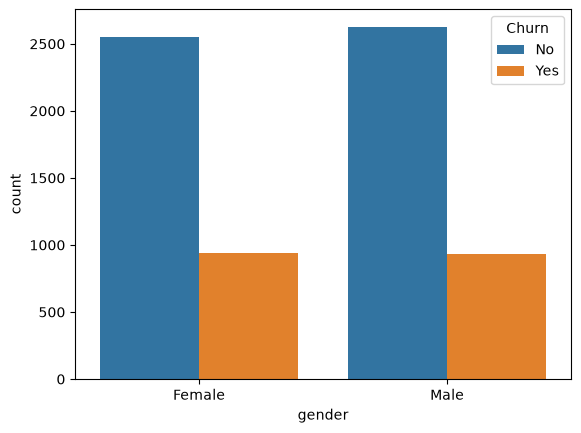

In [12]:
sns.countplot(x='gender', hue='Churn', data = df)

visualization

<Axes: xlabel='gender', ylabel='count'>

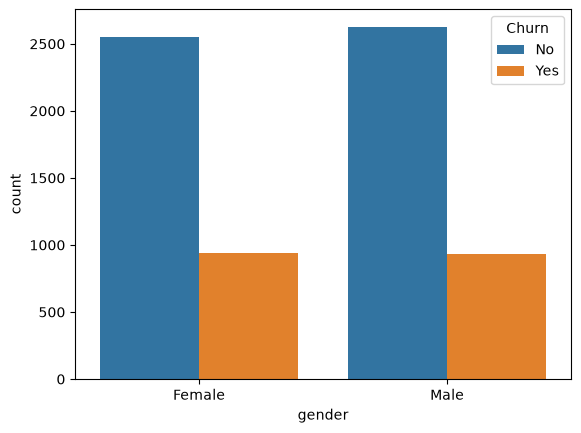

In [14]:
sns.countplot(x='gender', hue='Churn', data = df)


In [15]:
df['gender'].value_counts()


gender
Male      3555
Female    3488
Name: count, dtype: int64

<Axes: xlabel='MultipleLines', ylabel='count'>

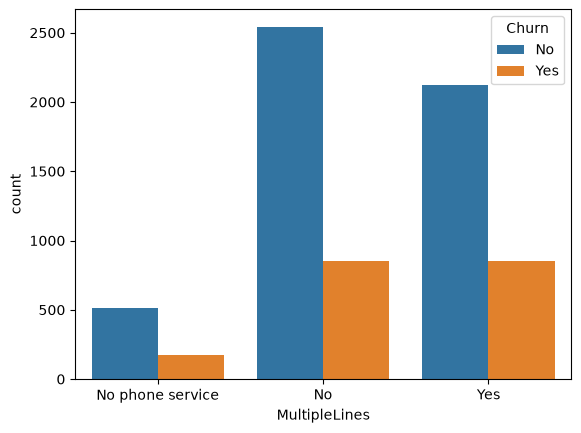

In [16]:
sns.countplot(x='MultipleLines', hue='Churn', data = df)


<Axes: xlabel='InternetService', ylabel='count'>

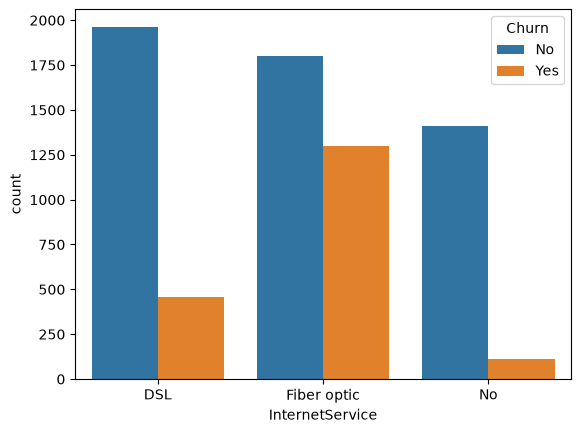

In [17]:
sns.countplot(x='InternetService', hue='Churn', data = df)

Data Preprocessing

as if value ar ordinal
we use level encoder for numerical value(0,1)

Drop Customer id

In [18]:
df = df.drop('customerID', axis=1)
df.shape

(7043, 20)

handle categorical value

In [37]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [49]:
for column in df.columns:
    if df[column].dtype == np.number:
        continue
df[column] = LabelEncoder().fit_transform(df[column])



In [50]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,1


In [51]:
x = df.drop('Churn',axis=1)
y = df['Churn']

In [52]:
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

Scaling the data set

In [60]:
from sklearn.preprocessing import StandardScaler
print(x.select_dtypes(include=['object', 'category']).columns.tolist())


[]


In [57]:
import pandas as pd

x = pd.get_dummies(
    x,
    drop_first=True,
    dtype=int
)

print(x.head())

   SeniorCitizen  tenure  MonthlyCharges  gender_Male  Partner_Yes  \
0              0       1           29.85            0            1   
1              0      34           56.95            1            0   
2              0       2           53.85            1            0   
3              0      45           42.30            1            0   
4              0       2           70.70            0            0   

   Dependents_Yes  PhoneService_Yes  MultipleLines_No phone service  \
0               0                 0                               1   
1               0                 1                               0   
2               0                 1                               0   
3               0                 0                               1   
4               0                 1                               0   

   MultipleLines_Yes  InternetService_Fiber optic  ...  TotalCharges_995.35  \
0                  0                            0  ...                   

In [58]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

feature_x = scaler.fit_transform(x)

print(feature_x[:5])

[[-0.44014635 -1.27744603 -1.16032292 ... -0.01191659 -0.01191659
  -0.01191659]
 [-0.44014635  0.06633966 -0.25962894 ... -0.01191659 -0.01191659
  -0.01191659]
 [-0.44014635 -1.23672525 -0.36266036 ... -0.01191659 -0.01191659
  -0.01191659]
 [-0.44014635  0.51426822 -0.74653546 ... -0.01191659 -0.01191659
  -0.01191659]
 [-0.44014635 -1.23672525  0.19736523 ... -0.01191659 -0.01191659
  -0.01191659]]


Split Data set

In [62]:
from sklearn.model_selection import train_test_split

In [70]:
xtrain,xtest, ytrain,ytest = train_test_split(feature_x, y, test_size=.25,random_state=42)


In [71]:
xtest

array([[-0.44014635, -1.27744603, -1.32816441, ..., -0.01191659,
        -0.01191659, -0.01191659],
       [-0.44014635,  0.35138511, -1.31320824, ..., -0.01191659,
        -0.01191659, -0.01191659],
       [-0.44014635,  0.79931367, -1.50930029, ..., -0.01191659,
        -0.01191659, -0.01191659],
       ...,
       [-0.44014635, -0.13726423,  0.20401242, ..., -0.01191659,
        -0.01191659, -0.01191659],
       [-0.44014635, -1.23672525, -0.99912861, ..., -0.01191659,
        -0.01191659, -0.01191659],
       [ 2.27197156,  0.84003445,  0.30039665, ..., -0.01191659,
        -0.01191659, -0.01191659]], shape=(1761, 6559))

Build Logistic Regression Model

In [72]:
from sklearn.linear_model import LogisticRegression


In [73]:
model = LogisticRegression()


In [74]:
model.fit(xtrain,ytrain)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [75]:
pred = model.predict(xtest)


In [76]:
pred

array([1, 0, 0, ..., 0, 1, 0], shape=(1761,))

Performance Metrics

In [ ]:

from sklearn.metrics import accuracy_score


In [79]:
# Accuracy score
accuracy_score(ytest,pred)

0.7836456558773425

In [80]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix

In [81]:
confusion_matrix(ytest,pred)

array([[1130,  152],
       [ 229,  250]])

In [82]:
#classification Report
from sklearn.metrics import classification_report
print(classification_report(ytest,pred))

              precision    recall  f1-score   support

           0       0.83      0.88      0.86      1282
           1       0.62      0.52      0.57       479

    accuracy                           0.78      1761
   macro avg       0.73      0.70      0.71      1761
weighted avg       0.77      0.78      0.78      1761

